In [1]:
import os
import open3d as o3d # open 3D / point cloud processing
import numpy as np #numpy
import matplotlib.pyplot as plt # plot 
import sklearn #ML / clustering
import plotly.graph_objects as go # plot with additional benefits
from sklearn.preprocessing import MinMaxScaler


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.



- read .pcd file 
- convert to numpy
- visualize using plotly, draw geometries
- https://www.open3d.org/docs/release/tutorial/visualization/visualization.html


In [2]:

path_pcd='TMS-SGI-TB50_Bollard.ply'
pcd1 = o3d.io.read_point_cloud(path_pcd) # object of type point cloud
print("point cloud as pcd in scene:\n{}".format(pcd1))

pcd1_np=np.asarray(pcd1.points) # convert to np array
print("point cloud as np in scene:\n{}".format(pcd1_np))
print("Shape of scene:\n {}".format(np.shape(pcd1_np)))

#plot pcd object usin gplotly #https://www.open3d.org/docs/latest/python_api/open3d.visualization.draw_plotly.html#open3d.visualization.draw_plotly
o3d.visualization.draw_plotly([pcd1]) 

#plot pcd object using open 3D  #draw_geometries
# o3d.visualization.draw_geometries_with_editing([pcd1],
#                                 window_name='Point cloud'
#                                 )

#plot using go. This needs numpy vectors
trace = go.Scatter3d(
    x=pcd1_np[:, 0], y=pcd1_np[:, 1], z=pcd1_np[:, 2],
    mode='markers',
    marker=dict(size=0.5, color='blue'),
    name='Point Cloud',
    showlegend=True
)

# Create figure with custom title
fig = go.Figure(data=[trace])
fig.update_layout(
                    title="Point cloud with go",
                    width=600,   # Set desired width
                    height=600,  # Set desired height
                    legend=dict(
                                x=0.9, 
                                y=0.9,
                                bgcolor='rgba(255,255,255,0.7)',
                                #bordercolor='black',
                                #borderwidth=0.5
                                )

                )
fig.show()



point cloud as pcd in scene:
PointCloud with 9843 points.
point cloud as np in scene:
[[183.58250427  50.0000267  417.62628174]
 [183.58250427  50.0000267  420.00073242]
 [179.85119629  50.0000267  417.62628174]
 ...
 [202.36184692  52.0000267  415.5012207 ]
 [202.29014587  52.0000267  414.87661743]
 [202.24967957  52.0000267  414.14892578]]
Shape of scene:
 (9843, 3)


- operations as - downsampling, estimate normal

In [3]:
#downsample to reduce points
downpcd = pcd1.voxel_down_sample(voxel_size=0.2) #downsample by 20%
downpcd_np=np.asarray(downpcd.points)

trace = go.Scatter3d(
    x=downpcd_np[:, 0], y=downpcd_np[:, 1], z=downpcd_np[:, 2],
    mode='markers',
    marker=dict(size=0.5, color='green'),
    name='Down sample point cloud',
    showlegend=True
)


fig = go.Figure(data=[trace])
fig.update_layout(
                    title="Point cloud with go",
                    width=800,   # Set desired width
                    height=800,  # Set desired height
                    legend=dict(
                                x=1, #x=0,1 - left, right
                                y=0.5, #y=0,1 - bottom, top
                                bgcolor='rgba(255,255,255,0.7)',
                                #bordercolor='black',
                                #borderwidth=0.5
                                font=dict(
                                          size=10,
                                          color='black'  
                                        )
                                )

                )
fig.show()

print("Original pcd shape: {}".format(np.shape(pcd1_np)))

print("Downsample pcd shape: {}".format(np.shape(downpcd_np)))


#find normal vertex
downpcd.estimate_normals(search_param=o3d.geometry.KDTreeSearchParamHybrid(radius=0.1, max_nn=30))
#o3d.visualization.draw_geometries([downpcd],point_show_normal=True)


Original pcd shape: (9843, 3)
Downsample pcd shape: (9765, 3)


- Normalize poind cloud

In [ ]:
# Find the overall min and max point (per axis)
min_vals = pcd1_np.min(axis=0)
max_vals = pcd1_np.max(axis=0)

# Compute range - min/max
rangee = max_vals - min_vals
max_range = np.max(rangee)  # Use the largest side to scale uniformly

# Normalize to [0, 1] based on full range
normalized_points = (pcd1_np - min_vals) / max_range

# Optional: center to [-0.5, 0.5]
#centered_points = normalized_points - 0.5 * (extent / max_range)

# Update the point cloud
pcd_scaled=o3d.geometry.PointCloud() #pcd object
pcd_scaled.points = o3d.utility.Vector3dVector(normalized_points) # assign points to pcd_scaled 
pcd_scaled_np=np.asarray(pcd_scaled.points) # (9843, 3) # convert pcd_scaled to np

# Visualize
#o3d.visualization.draw_plotly([pcd_scaled])

trace = go.Scatter3d(
    x=pcd_scaled_np[:, 0], y=pcd_scaled_np[:, 1], z=pcd_scaled_np[:, 2],
    mode='markers',
    marker=dict(size=0.5, color='blue'),
    name='Normalized point cloud',
    showlegend=True
)


fig = go.Figure(data=[trace])
fig.update_layout(
                    title="Normalized point cloud ",
                    scene=dict(aspectmode='data'), # keeps aspect ration fit to data
                    width=600,   # Set desired width
                    height=600,  # Set desired height
                    legend=dict(
                                x=1, #x=0,1 - left, right
                                y=0.5, #y=0,1 - bottom, top
                                bgcolor='rgba(255,255,255,0.7)',
                                #bordercolor='black',
                                #borderwidth=0.5
                                font=dict(
                                          size=10,
                                          color='black'  
                                        )
                                )

                )
fig.show()

# Lab work  

- Create a bounding box around the normalize pcd, as shown in figure below - bollard-bb.png  

- See -https://www.open3d.org/docs/latest/python_api/open3d.geometry.OrientedBoundingBox.html#open3d.geometry.OrientedBoundingBox.get_minimal_oriented_bounding_box
- to draw line - https://www.open3d.org/docs/latest/tutorial/visualization/visualization.html

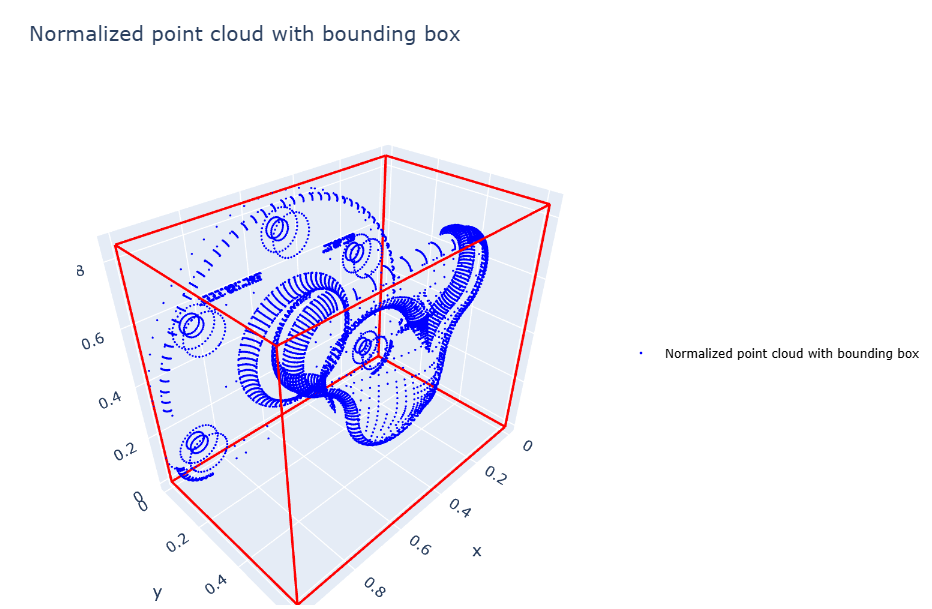

- # Lab work: 
    - Generate a point cloud object and assign points to it. 
    - Ref:https://www.open3d.org/docs/latest/tutorial/t_geometry/pointcloud.html
    - Create two  numpy array (arr1 and arr2) of dimension 100x3. arr1 is sampled from gaussian distribution with mean 1 and standard deviation 2. arr2 is sampled from mean 2 and standard deviation 4.  
    Note: This is a cluster with 100 points and each points have 3 co-ordinate x,y,z

    - Convert both arr1 and arr2 to pointcloud - pcd1 and pcd2 respectively 
    - Find the min and max value of pcd1 and pcd2   along all axis -x,y, z
    - Find normalized points for each pointcloud pcd1 and pcd2 - (pcd - min)/ max(range). Call it normpcd1, normpcd2
    - Visualize pcd1, pcd2, normpcd1, normpcd2

- K mean cluster

In [16]:
# Apply KMeans #https://scikit-learn.org/stable/modules/generated/sklearn.cluster.k_means.html
k = 6  # Number of clusters
kmeans = sklearn.cluster.KMeans(n_clusters=k, random_state=0).fit(pcd_scaled.points) #random_state= int control the random number generator used
labels_kmeans, centroid_kmeans = kmeans.labels_, kmeans.cluster_centers_ # labels_kmeans gives associations of points to cluster, centroid_kmeans give centroid of clusters

# Assign cluster colors
colors = plt.get_cmap("tab20")(labels_kmeans / (k - 1))[:, :3]  # Remove alpha
pcd_scaled.colors = o3d.utility.Vector3dVector(colors)

# Visualize
o3d.visualization.draw_plotly([pcd_scaled])

labels_kmeans, centroid_kmeans

(array([4, 4, 4, ..., 4, 4, 4], shape=(9843,), dtype=int32),
 array([[0.57781987, 0.53796567, 0.35137718],
        [0.7515964 , 0.07376403, 0.45485635],
        [0.32535206, 0.47863474, 0.52313447],
        [0.7683813 , 0.47965389, 0.62836001],
        [0.2673099 , 0.07283008, 0.48421535],
        [0.17120126, 0.48715898, 0.69594541]]))

DBSCAN clustering

In [6]:

#https://www.open3d.org/docs/release/python_api/open3d.geometry.PointCloud.html#open3d.geometry.PointCloud.cluster_dbscan
#eps defines The maximum distance between two samples for one to be considered as in the neighborhood of the other and 
# min_points defines The number of samples (or total weight) in a neighborhood for a point to be considered as a core point. 
# The function returns labels, where the label -1 indicates noise.

labels = np.array(pcd_scaled.cluster_dbscan(eps=0.1, min_points=50, print_progress=True))  #eps=0.1, min_points=50 - 4 clusters, eps=0.2, min_points=50 - 2 cluster
max_label = labels.max()

# assign colors to individual clusters
if max_label == -1:
    # All points are outliers: assign black
    colors = np.tile([0.0, 0.0, 0.0], (len(labels), 1))
else:
    cmap = plt.get_cmap("tab20")
    #colors = cmap((labels % 20.0) / 20.0)[:, :3]  # RGB  # tab20 has 20 colours. %20 resticts the cluster 0-19, 21st cluster has same color as 1. But I have used 10, to get contrast visualization
    colors = cmap((labels % (max_label+1)) / (max_label+1))[:, :3]
    colors[labels == -1] = [0, 0, 0]  # Black for outliers
print(f"point cloud has {max_label + 1} clusters")

pcd_scaled.colors = o3d.utility.Vector3dVector(colors[:, :3])
o3d.visualization.draw_plotly([pcd_scaled])
#o3d.visualization.draw_geometries([pcd1])

point cloud has 4 clusters


# Lab -work:   
- try playing with eps, and see its effect
-  eps=0.15, min_points=50
-  eps=0.05, min_points=50;  
-  eps=0.08, min_points=50 

-  DBSCAN

In [7]:
#pcd_pts=np.asarray(pcd1.points) #pcd_scaled_np     pcd1
l=np.unique(labels) # unique entires in labels [-1,0,1,2,3]
#c=[]
for j in l:
    ind=np.where(labels==j) #find the index of elements in vector labels whose value is j. e.g. find the index of elements whose value is -1 in vector labels -- gives a row vector
    if j==-1:
        c=pcd_scaled_np[ind] #pcd_scaled_np is 9843x3  #If x is a 2D array, x[ind] returns a 1D row 
    if j==0:
        c0=pcd_scaled_np[ind]
    if j==1:
        c1=pcd_scaled_np[ind]
    if j==2:
        c2=pcd_scaled_np[ind]
    if j==3:
        c3=pcd_scaled_np[ind]
        

#cluster=[c, c0, c1, c2, c3]  

#import pandas as pd
#series = pd.Series([c,c0,c1,c2,c3]) #save multiple cluster as pandas series


cl=np.array([c, c0, c1, c2, c3], dtype=object) # create array of array. cl[0] contains cluster 1 as np array; dtype=object is important as cl contain array of different dimenstion

Find the centroid of an cluster and plot both - cluster and centroid

In [8]:

# conevrt 2nd cluster numpy array and its centroid to pcd and plot them in red/green


mean_c = [np.mean(cl[2], axis=0)] # must be a matrix/vector not list cl[0] - first cluster, cl[1] - second cluster ...

# Create Open3D point cloud object
pcd_c = o3d.geometry.PointCloud()
pcd_mean_c=o3d.geometry.PointCloud()

# Assign points
pcd_c.points = o3d.utility.Vector3dVector(cl[2]) #c[0] cluster[0][0]
pcd_mean_c.points = o3d.utility.Vector3dVector(mean_c)

#convert to np
pcd_c_np=np.asarray(pcd_c.points)
pcd_mean_c_np=np.asarray(pcd_mean_c.points)

#visualize option 1
# pcd_c.paint_uniform_color([1, 0, 0])  # Red
# pcd_mean_c.paint_uniform_color([0, 1, 0])  # Green
# o3d.visualization.draw_plotly([pcd_c, pcd_mean_c])

#visualize option 2


cluster2 = go.Scatter3d(
    x=pcd_c_np[:, 0], y=pcd_c_np[:, 1], z=pcd_c_np[:, 2],
    mode='markers',
    marker=dict(size=3, color='red'),
    name='cluster2'
)

centroid2 = go.Scatter3d(
    x=pcd_mean_c_np[:, 0], y=pcd_mean_c_np[:, 1], z=pcd_mean_c_np[:, 2],
    mode='markers',
    marker=dict(size=5, color='green'),
    name='centroid2'
)

fig = go.Figure(data=[cluster2, centroid2])
fig.update_layout(
                    title="Cluster 2 ",
                    #scene=dict(aspectmode='data'),
                    width=800,   # Set desired width
                    height=600,  # Set desired height
                    legend=dict(
                                x=1, #x=0,1 - left, right
                                y=0.5, #y=0,1 - bottom, top
                                bgcolor='rgba(255,255,255,0.7)',
                                #bordercolor='black',
                                #borderwidth=0.5
                                font=dict(
                                          size=10,
                                          color='black'  
                                        )
                                )

                )
fig.show()



# Lab work: 

Find all the clusters and its centroid as shown below.


![alt text](bollard-cluster-centroid.png)

# Labwork: 
- Plot individual clusters and print how many points each has  

# RANSAC
Find inlier and outlier in synthetic data

In [9]:
import numpy as np
import plotly.graph_objects as go

# Example inlier and outlier arrays: (N, 3)
inlier_points = np.random.rand(100, 3)
outlier_points = np.random.rand(50, 3) + 1.0  # shifted for clarity

# Create figure
fig = go.Figure()

# Inliers
fig.add_trace(go.Scatter3d(
    x=inlier_points[:, 0],
    y=inlier_points[:, 1],
    z=inlier_points[:, 2],
    mode='markers',
    marker=dict(size=3, color='green'),
    name='Inliers'
))

# Outliers
fig.add_trace(go.Scatter3d(
    x=outlier_points[:, 0],
    y=outlier_points[:, 1],
    z=outlier_points[:, 2],
    mode='markers',
    marker=dict(size=3, color='red'),
    name='Outliers'
))

# Layout
fig.update_layout(
    scene=dict(aspectmode='data'),
    title='Inliers and Outliers',
    legend=dict(x=0.8, y=0.9)
)

fig.show()


In [10]:
#Ref: https://www.open3d.org/docs/latest/tutorial/geometry/pointcloud.html

#choose cluster 3  i.e. last cluster cluster 5
# cluster5=cluster_points
# cluster5_np=np.asarray(cluster_points)

# Create Open3D point cloud object
cluster2 = o3d.geometry.PointCloud()
# Assign points
cluster2.points = o3d.utility.Vector3dVector(cl[2]) 
#convert to numpy
cluster2_np=np.asarray(cluster2.points)

#distance_threshold:Maximum distance from the point to the plane for it to be considered an inlier
#inliers: A list of indices of points in the point cloud that are within distance_threshold of the plane (i.e., lie on or near the plane).
plane_model2, inliers2 = cluster2.segment_plane(distance_threshold=0.01,  #distance_threshold=0.1 you get the top of bollard; distance_threshold=0.03/0.01 get the boundary of top surface of bollard
                                         ransac_n=3,
                                         num_iterations=500)

[a, b, c, d] = plane_model2
print(f"Plane equation: {a:.2f}x + {b:.2f}y + {c:.2f}z + {d:.2f} = 0")

inlier_cloud2 = cluster2.select_by_index(inliers2)
inlier_cloud2.paint_uniform_color([1.0, 0, 0])
outlier_cloud2 = cluster2.select_by_index(inliers2, invert=True) #Returns all points NOT in the inliers5 list — i.e., the outliers. The invert=True flag means: exclude the listed indices.

# fig = go.Figure(data=[inlier_cloud2, outlier_cloud2])
# fig.update_layout(    
#     #scene=dict(aspectmode='data'),
#     legend=dict(
#         #title='Legend',
#         x=0.9, # tune to place legend close to figure
#         y=0.9,
#         #bgcolor='rgba(255,255,255,0.5)'
#     ),
#     #height=400, width=800
#     ) 
# fig.show()
#o3d.visualization.draw_plotly([inlier_cloud2, outlier_cloud2 ])
# o3d.visualization.draw_geometries([inlier_cloud2, outlier_cloud2],
#                                   zoom=0.8,
#                                   front=[-0.4999, -0.1659, -0.8499],
#                                   lookat=[2.1813, 2.0619, 2.0999],
#                                   up=[0.1204, -0.9852, 0.1215])

#make numpy array for plotting and data operations
inlier_cloud2_np=np.asarray(inlier_cloud2.points)
outlier_cloud2_np=np.asarray(outlier_cloud2.points)

fig = go.Figure()

# Inliers
fig.add_trace(go.Scatter3d(
    x=inlier_cloud2_np[:, 0],
    y=inlier_cloud2_np[:, 1],
    z=inlier_cloud2_np[:, 2],
    mode='markers',
    marker=dict(size=2, color='green'),
    name='Inliers'
))

# Outliers
fig.add_trace(go.Scatter3d(
    x=outlier_cloud2_np[:, 0],
    y=outlier_cloud2_np[:, 1],
    z=outlier_cloud2_np[:, 2],
    mode='markers',
    marker=dict(size=2, color='red'),
    name='Outliers'
))

# Layout
fig.update_layout(
    scene=dict(aspectmode='data'),
    title='Inliers and Outliers',
    legend=dict(x=0.6, y=0.6)
)

fig.show()

print("Inlier:{}, Outlier:{}".format(np.shape(inlier_cloud2_np)[0], np.shape(outlier_cloud2_np)[0]) )


Plane equation: -0.00x + 1.00y + 0.03z + -0.54 = 0


Inlier:1361, Outlier:4073


# plot inliers such that distance of each point in inlier is represented by colour, fit a plane to inlier, draw local coordinate i.e. pose of plane in space

In [11]:
#plot inliers such that distance of each point inlier is represented by colour, fit a plane to inlier, draw local coordinate i.e. pose of plane in space 

# computes the perpendicular distance from each point in a point cloud (cluster2) to a plane
numerators = np.abs(inlier_cloud2_np @ np.array([a, b, c]) + d) #cluster2_np inlier_cloud2_np
#numerators = np.abs(np.dot(points5,np.array([a, b, c])) + d)
denominator = np.sqrt(a**2 + b**2 + c**2)
distances = numerators / denominator

print("Mean distance to plane:", np.mean(distances))

# color point by distances

# Normalize distances for color
# colors = plt.get_cmap('jet')((distances - distances.min()) / (distances.ptp()))
# cluster2.colors = o3d.utility.Vector3dVector(colors[:, :3])
#o3d.visualization.draw_plotly([cluster2])


#plot plane, and perpendicular distances of each point to this plane

# create plane grid
xlim = np.linspace(inlier_cloud2_np[:, 0].min(), inlier_cloud2_np[:, 0].max(), 10)
ylim = np.linspace(inlier_cloud2_np[:, 1].min(), inlier_cloud2_np[:, 1].max(), 10)
#x_grid, y_grid = np.meshgrid(xlim, ylim)
#z_grid = -(a * x_grid + b * y_grid + d) / c

scaler = MinMaxScaler()


xlim=scaler.fit_transform(xlim.reshape(-1, 1)) #makes it 2D
ylim=scaler.fit_transform(ylim.reshape(-1, 1)) #makes it 2D
x_grid, y_grid = np.meshgrid(xlim, ylim)

z_grid = -(a * x_grid + b * y_grid + d) / c
z_grid = scaler.fit_transform(z_grid)


#plane
trace_plane = go.Surface(
    x=x_grid, y=y_grid, z=z_grid,
    colorscale='greys',
    opacity=0.5,
    showscale=False,
    name='Fitted Plane'
)

#point cloud
trace_points = go.Scatter3d(
    x=inlier_cloud2_np[:, 0],
    y=inlier_cloud2_np[:, 1],
    z=inlier_cloud2_np[:, 2],
    mode='markers',
    marker=dict(
        size=3,
        color=distances,            # Use distances for color mapping
        colorscale='jet',       # Choose any Plotly colorscale
        colorbar=dict(
            title='Distance', 
            x=0.95,     # Horizontal position (0=left, 1=right)
            y=0.5,      # Vertical position (0=bottom, 1=top)
            len=0.5,    # Height of the colorbar (fraction)
            ),
        #legend=dict(x=0.6, y=0.6),
        showscale=True
    ),
    name='Points colored by distance'
)

# --- Compute normal vector at centroid --- 
#Local coordinate frame has 3 axis – X, and Y tangent to surface, Z axis normal to surface
#However, The normal vector alone gives you just one direction: the Z-axis of the local frame.
#You must compute the other two (orthogonal to the normal) to complete the frame.

# visualize the local coordinate frame (X, Y, Z axes) of the normal — i.e., draw three perpendicular arrows showing the orientation of the plane 
#Red = X axis (in-plane), Green = Y axis (in-plane), Blue = Z axis (normal to the plane)

# -- Compute center of point cloud --
origin = np.mean(inlier_cloud2_np, axis=0)

# -- Plane normal (Z axis of local frame) --
z_axis = np.array([a, b, c])
z_axis = z_axis / np.linalg.norm(z_axis)

# -- Choose a vector not parallel to z_axis to compute X and Y --
not_z = np.array([1, 0, 0]) if abs(z_axis[0]) < 0.99 else np.array([0, 1, 0])
x_axis = np.cross(not_z, z_axis)
x_axis = x_axis / np.linalg.norm(x_axis)

y_axis = np.cross(z_axis, x_axis)
y_axis = y_axis / np.linalg.norm(y_axis)

# -- Set axis length --
length = 0.2

# # -- local coordinate frame parameters. Plot arrows for X, Y, Z axes using Scatter3d lines --
# axis_traces = []
colors = ['red', 'green', 'blue']
axes = [x_axis, y_axis, z_axis]
labels = ['X axis', 'Y axis', 'Z axis']

fig = go.Figure()

# Add axis lines and tips
for i, vec in enumerate(axes):
    tip = origin + vec * length

    fig.add_trace(go.Scatter3d(
        x=[origin[0], tip[0]],
        y=[origin[1], tip[1]],
        z=[origin[2], tip[2]],
        mode='lines+markers+text',
        line=dict(color=colors[i], width=2),
        marker=dict(size=4, color=colors[i]),
        name=labels[i],
        text=[None, labels[i]],
        textposition='top center'
    ))

#Red = X axis (in-plane), Green = Y axis (in-plane), Blue = Z axis (normal to the plane)

fig.add_trace(trace_points)
fig.add_trace(trace_plane)



# === Combine and Plot ===
#fig = go.Figure(data=[ trace_points, trace_localcoordinate]) #trace_points, trace_plane, trace_localcoordinate
fig.update_layout(
    scene=dict(aspectmode='data'), #data
    width= 800, 
    height=700,
    #legend=dict(x=0.9, y=0.9, xanchor='left',yanchor='top',),
    title='Cluster, centroid, plane, and plane\'s pose',
    legend=dict(x=0.9, y=0.9),
    margin=dict(l=0, r=0, t=0, b=0)
)

fig.show()
# building local coordinate frames using normals 
# A local frame is like a mini 3D coordinate system anchored at a point. It consists of:
# An origin (a 3D point)
# Three orthogonal unit vectors:
# Z-axis: Usually the normal vector (perpendicular to the surface)
# X and Y axes: Tangent vectors lying on the surface

#Rotation matrix i.e rotation of object 
R = np.column_stack((x_axis, y_axis, z_axis))  # 3×3 rotation matrix, first col is coordinate of x axis, second col - yaxis, third col - z axis
print(R)

#transformation matrix
T = np.eye(4)
T[:3, :3] = R

#origin, centroid of object
T[:3, 3] = origin  # The point where the frame is located, usually centroid of object
print("Homogeneous Transformation :\n{}".format(T))

#visualize the frame in open 3D

frame = o3d.geometry.TriangleMesh.create_coordinate_frame(size=0.1)
frame.transform(T)
o3d.visualization.draw_geometries([cluster2, frame]) # A 3D coordinate frame (red = X, green = Y, blue = Z) located at the centroid of the plane and aligned with its normal


Mean distance to plane: 0.004690183721605494


[[ 0.00000000e+00  9.99991042e-01 -4.23266228e-03]
 [-3.28518204e-02  4.23037762e-03  9.99451280e-01]
 [ 9.99460233e-01  1.39050661e-04  3.28515261e-02]]
Homogeneous Transformation :
[[ 0.00000000e+00  9.99991042e-01 -4.23266228e-03  5.06619678e-01]
 [-3.28518204e-02  4.23037762e-03  9.99451280e-01  5.26897784e-01]
 [ 9.99460233e-01  1.39050661e-04  3.28515261e-02  5.69888117e-01]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


In [12]:
#plot axes of unit norm
import numpy as np
import plotly.graph_objects as go
fig = go.Figure()

# Add axis lines and tips
for i, vec in enumerate(axes):
    tip = origin + vec * length

    fig.add_trace(go.Scatter3d(
        x=[origin[0], tip[0]],
        y=[origin[1], tip[1]],
        z=[origin[2], tip[2]],
        mode='lines+markers+text',
        line=dict(color=colors[i], width=2),
        marker=dict(size=6, color=colors[i]),
        name=labels[i],
        text=[None, labels[i]],
        textposition='top center'
    ))

fig.update_layout(
    scene=dict(aspectmode='cube'),
    legend=dict(x=1, y=1),
    width=600,
    height=600
)

fig.show()


In [13]:
for i, vec in enumerate(axes):
    print(f"{labels[i]} axis vector: {vec}, norm: {np.linalg.norm(vec):.6f}")

X axis axis vector: [ 0.         -0.01844509  0.99982987], norm: 1.000000
Y axis axis vector: [ 9.99997383e-01 -2.28726064e-03 -4.21959046e-05], norm: 1.000000
Z axis axis vector: [0.00228765 0.99982726 0.01844504], norm: 1.000000


In [14]:

#check for orthogonality of axes -
print("z_axis (normal):", z_axis)
print("x_axis:", x_axis)
print("y_axis:", y_axis)
print("Dot products (should be ~0):", np.dot(x_axis, y_axis), np.dot(x_axis, z_axis), np.dot(y_axis, z_axis))

z_axis (normal): [0.00228765 0.99982726 0.01844504]
x_axis: [ 0.         -0.01844509  0.99982987]
y_axis: [ 9.99997383e-01 -2.28726064e-03 -4.21959046e-05]
Dot products (should be ~0): 0.0 0.0 -2.1546400595781265e-19


# Lab work: . This is one example. Your clusters might be different depending upon your parameters.
- Cluster the bollard and find the local frame of each cluster 



![alt text](bollard-cluster-pose-1.png)



# Lab work: Read .pcap and .json file and convert to series of .pcd files

In [ ]:

from ouster.sdk.examples.pcap import pcap_to_pcd
pcap_to_pcd("swinging_load.pcap", num=0, pcd_dir='./pcd_output', pcd_base="frame", pcd_ext="pcd")

In [20]:
#read multiple pcd files
import open3d as o3d

# Example: load multiple PCD files
file_paths = ["pcd_output/frame__000050.pcd", "pcd_output/frame__000100.pcd"]
list_of_pcd = [o3d.io.read_point_cloud(path) for path in file_paths]

#visualize them all
#o3d.visualization.draw_geometries(list_of_o3d_pointclouds)

for i, pcd in enumerate(list_of_pcd):
    vis = o3d.visualization.Visualizer()
    vis.create_window(window_name=f"Point Cloud {i+1}")
    vis.add_geometry(pcd)
    vis.run()  # blocks until the window is closed
    vis.destroy_window()


# Find the equation of plane passing through three points. Find its normal vector, and distance 

In [111]:
import numpy as np
import sympy as sym

A=np.array([3,1,1])
B=np.array([1,4,2])
C=np.array([1,3,4])

AB=B-A
AC=C-A

N=np.cross(AB,AC)

x=sym.Symbol('x')
y=sym.Symbol('y')
z=sym.Symbol('z')

X=np.array([x,y,z])

plane=np.dot(N,X-A)

#equation of plane
print (r'Equation of plane is', plane)

#coefficient of plane
a=plane.coeff(x)
b=plane.coeff(y)
c=plane.coeff(z)
d=plane.subs({x: 0, y: 0, z: 0})

print("Coefficients (a, b, c, d):", (a,b,c,d))


#Normal vector n=[a,b,c]. is the normal vector of the plane → this gives the orientation of the surface. 
# This vector is perpendicular to the plane and defines its orientation in 3D space
print ('Normal vector of plane:', N)

#normal magnitude
mag_N=np.linalg.norm(N)
print('Normal magnitude:', mag_N)

#parameter d determines the distance/translation of plane from origin
norm_N=a**2+b**2+c**2
dist=float(d/sym.sqrt(norm_N))
print('Distance of plane from origin is', np.abs(dist))

#find distance of point E(1,7,4) from this plane
E=np.array([1,7,4])
distance_point_to_plane=plane.evalf(subs={x:E[0], y:E[1], z:E[2]})/(sym.sqrt(norm_N))

print('Distance of pt E from plane is', float(distance_point_to_plane))


Equation of plane is 7*x + 4*y + 2*z - 27
Coefficients (a, b, c, d): (7, 4, 2, -27)
Normal vector of plane: [7 4 2]
Normal magnitude: 8.306623862918075
Distance of plane from origin is 3.2504180333157686
Distance of pt E from plane is 1.9261736493723072


# find the following:
Find the equation of plane passing through A(4,1,1), B(1,7,2) and C(1,8,4)

Find its model parameters

Find its normal vector

Find magnitude of normal vector

Find the distance of normal vector from origin

Find the distance of plane from point (1,1,1)


In [112]:
import numpy as np
import sympy as sym

A=np.array([4,1,1])
B=np.array([1,7,2])
C=np.array([1,8,4])

AB=B-A
AC=C-A

N=np.cross(AB,AC)

x=sym.Symbol('x')
y=sym.Symbol('y')
z=sym.Symbol('z')

X=np.array([x,y,z])

plane=np.dot(N,X-A)

#equation of plane
print (r'Equation of plane is', plane)

#coefficient of plane
a=plane.coeff(x)
b=plane.coeff(y)
c=plane.coeff(z)
d=plane.subs({x: 0, y: 0, z: 0})

print("Coefficients (a, b, c, d):", (a,b,c,d))


#Normal vector n=[a,b,c]. is the normal vector of the plane → this gives the orientation of the surface. 
# This vector is perpendicular to the plane and defines its orientation in 3D space
print ('Normal vector of plane:', N)

#normal magnitude
mag_N=np.linalg.norm(N)
print('Normal magnitude:', mag_N)

#parameter d determines the distance/translation of plane from origin
#dist=d/(np.linalg.norm(N))
norm_N=a**2+b**2+c**2
dist=float(d/sym.sqrt(norm_N))

print('Distance of plane from origin is', np.abs(dist))

#find distance of point E(1,7,4) from this plane
E=np.array([1,1,1])
distance_point_to_plane=plane.evalf(subs={x:E[0], y:E[1], z:E[2]})/(sym.sqrt(norm_N))

print('Distance of pt E from plane is', float(abs(distance_point_to_plane)))


Equation of plane is 11*x + 6*y - 3*z - 47
Coefficients (a, b, c, d): (11, 6, -3, -47)
Normal vector of plane: [11  6 -3]
Normal magnitude: 12.884098726725126
Distance of plane from origin is 3.6479074708197645
Distance of pt E from plane is 2.5612967348308984


# Use sympy and built in libraries to define plane, vector, distance ...

In [1]:

from sympy import symbols, Plane, Point3D


#define a plane given by three points in 3D
a=Plane(Point3D(3,1,1), Point3D(1,4,2), Point3D(1,3,4)) # gives p1 and normal vector
print('Equation of plane:', a)

#find normal vector of plane a
print(f'Normal vector of {a} is {a.normal_vector}')

#distance of a point b from plane
b = Point3D(0, 0, 0)  #define point b (1, 7, 4)
dist_ab=float(a.distance(b))
print(f'Distance of {b} from  {a} is {dist_ab}')

Equation of plane: Plane(Point3D(3, 1, 1), (7, 4, 2))
Normal vector of Plane(Point3D(3, 1, 1), (7, 4, 2)) is (7, 4, 2)
Distance of Point3D(0, 0, 0) from  Plane(Point3D(3, 1, 1), (7, 4, 2)) is 3.2504180333157686
